# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [2]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [3]:
!nvidia-smi

Wed Aug 27 20:48:03 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A30                     Off |   00000000:99:00.0 Off |                    0 |
| N/A   36C    P0             31W /  165W |       1MiB /  24576MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [8]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [9]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "jacobi"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = True  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    model = "gpt4olatest"  # (max token = 200000)
    model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt4olatest"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model = "qwen3-coder:latest"  # context 262144
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "mtdTEST_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        "base_v1_optimization_methods",
        "base_v2_energy_J",
        "base_v2_avg_power_W",
        "base_v2_runtime_s",
        "base_v2_valid",
        "base_v2_selfcorrections",
        "base_v2_energy_diff",
        "base_v2_avg_power_diff",
        "base_v2_runtime_diff",
        "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 08-27-2025_t15_48_28
Application: jacobi

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpt4olatest
Model coder: gpt4olatest
Model judge: gpt4olatest
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpt4olatest/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI_dev/source_codes/HeCBench/jacobi/jacobi-cuda_main
initial_dir:  /home/cc/lassi/LASSI_dev
directory_path:  /home/cc/lassi/LASSI_dev/source_codes/HeCBench/jacobi
executable:  jacobi-cuda_main
Working directory: /home/cc/lassi/LASSI_dev/source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

running: executable -  jacobi-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00770316 (s)
PASS
Total elapsed time: 13.38 seconds

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


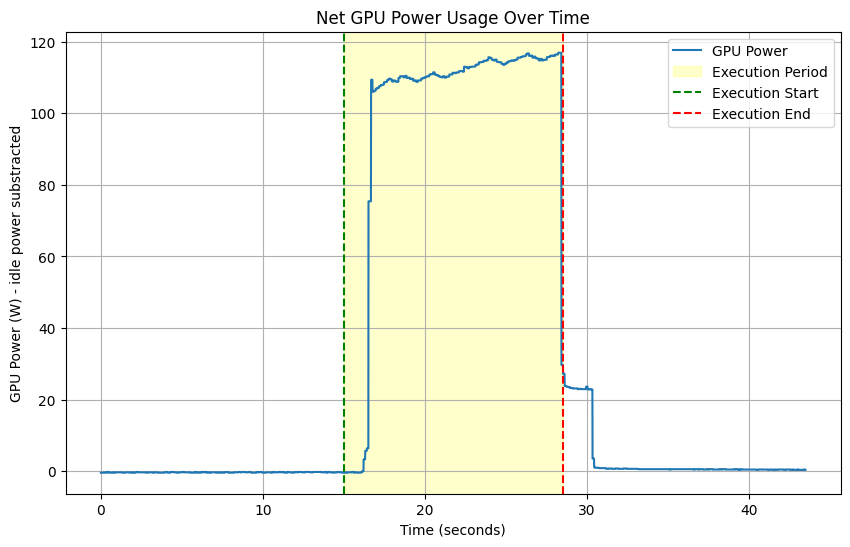

Start time: 15.0 -- End time: 28.498
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000371 kWh
  0.3711 Wh
  1336.07 J
Average GPU power: 99.04 W +/- 35.66 
 with sample standard deviation.
Net Energy During Exe Runtime:   1336.07 J
Code execution duration:  13.50 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.80 W, P0



Measure system idle power...
Duration for idle time measurement: 13.5
GPU power data has been written to idle__gpu_net_power_results.csv


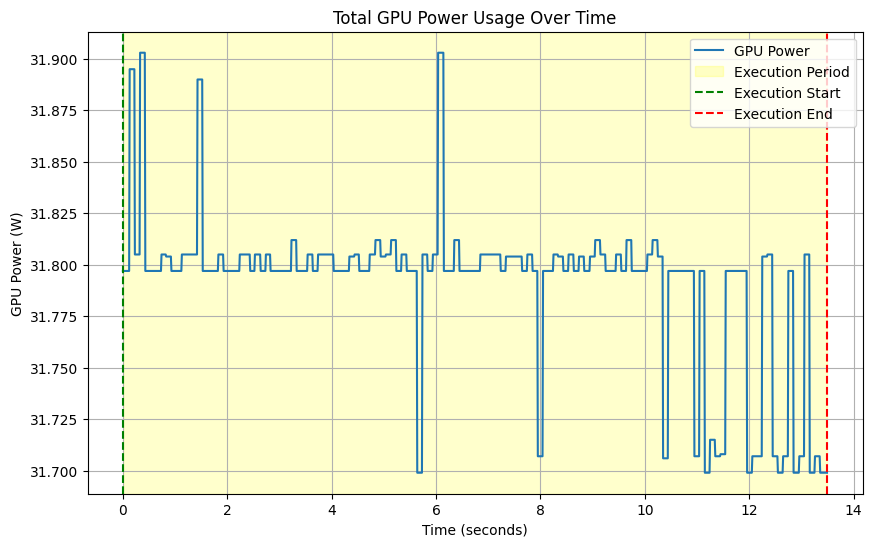

Start time: 0 -- End time: 13.498
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000119 kWh
  0.1192 Wh
  429.17 J
Average GPU power: 31.79 W +/- 0.04 
 with sample standard deviation.
Total Energy During Exe Runtime:   429.17 J
Code execution duration:  13.50 seconds
----------------------------------------------------------------------------------------------------------------------------------------

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- STARTING STAGE 1: STANDALONE BASE LLM REFACTORING  -----



--> ... prompt LLM to perform code analysis.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    You are a formal methods and parallel programm



----- LLM RESPONSE: code analysis -----



```json
=====
{
  "assumptions": [
    "The grid and block dimensions are fixed at 16x16, and the problem size (N) is a multiple of 16.",
    "The input data is initialized with sinusoidal boundary conditions, and the interior points are initialized to zero.",
    "The Jacobi relaxation method is used for solving a 2D Laplace equation iteratively.",
    "The error is computed as the L2-norm of the difference between successive iterations, normalized by the number of data points.",
    "The maximum number of iterations is capped at 10,000 to prevent infinite loops.",
    "The shared memory tile size is 18x18 to accommodate a 16x16 block with a 1-cell halo on all sides."
  ],
  "invariants": [
    "The boundary values of the grid remain constant throughout the computation.",
    "The grid dimensions (N x N) do not change during execution.",
    "The error value is reduced in each iteration until it converges below the specified tolerance or the maximum number of iterations is reached.",
    "The shared memory tile is always synchronized before being accessed by threads.",
    "The atomic addition to the global error variable ensures thread-safe updates."
  ],
  "design_patterns": [
    "Stencil computation: The Jacobi relaxation step involves a 5-point stencil operation.",
    "Shared memory tiling: Shared memory is used to load a tile of the grid, including halo regions, to reduce global memory accesses.",
    "Reduction: A hierarchical reduction is performed to compute the L2-norm of the error using warp-level and block-level reductions.",
    "Explicit memory management: Host and device memory are explicitly allocated, initialized, and deallocated.",
    "Iterative refinement: The algorithm iteratively refines the solution until convergence criteria are met."
  ],
  "memory_access_patterns": [
    "Global memory reads and writes occur in a coalesced manner for the main grid data.",
    "Shared memory is used to store a tile of the grid, including halo regions, to minimize global memory accesses.",
    "Boundary conditions are accessed directly from global memory without using shared memory.",
    "The error variable is updated atomically in global memory to ensure correctness in a parallel environment."
  ],
  "memory_allocation_deallocation": [
    "Host memory is allocated using `aligned_alloc` for the `f` and `f_old` arrays.",
    "Device memory is allocated using `cudaMalloc` for `d_f`, `d_f_old`, and `d_error`.",
    "Host memory is deallocated using `free`.",
    "Device memory is deallocated using `cudaFree`."
  ],
  "other_key_characteristics": [
    "The code uses a fixed block size of 16x16 threads, which matches the shared memory tile size.",
    "The `jacobi_step` kernel uses shared memory to optimize memory access and reduce global memory traffic.",
    "The `swap_data` kernel explicitly copies data from `d_f` to `d_f_old` instead of using a pointer swap.",
    "The error computation involves a reduction operation, which is performed in two stages: warp-level and block-level.",
    "The code uses `cudaMemcpy` to transfer data between host and device memory.",
    "The convergence criteria are based on both the error tolerance and the maximum number of iterations."
  ]
}
=====
```


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 2208)


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 

Refactor the following CUDA C++ code to optimize energy efficiency by reducing GPU energy consumption, while preserving all functionality.

[START OF CODE TO REFACTOR]
// Copyright (c) 2021, NVIDIA CORPORATION.
// Licensed under the Apache License, Version 2.0 (the "License");
// you may not use this file except in compliance with the License.
// You may obtain a copy of the License at
//
//     http://www.apache.org/licenses/LICENSE-2.0
//




----- THE GENERATED CODE -----

(hidden)



*** DEBUG: code_version: 0 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28.cu', '-o', '/home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28/jacobi-cuda_main_ee_refactorco

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28/jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28
initial_dir:  /home/cc/lassi/LASSI_dev
directory_path:  /home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28
executable:  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28
Working directory: /home/cc/lassi/LASSI_dev/generated_codes/experiment/mtdTEST_gpt4olatest_jacobi_ee__08-27-2025_t15_48_28
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28', '']

running: executable -  jacobi-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt4olatest_jacobi_ee_08-27-2025_t15_48_28

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Error after iteration 0 = 0.00390613
Error after iteration 1000 = 1.96071e-05
Error after iteration 20

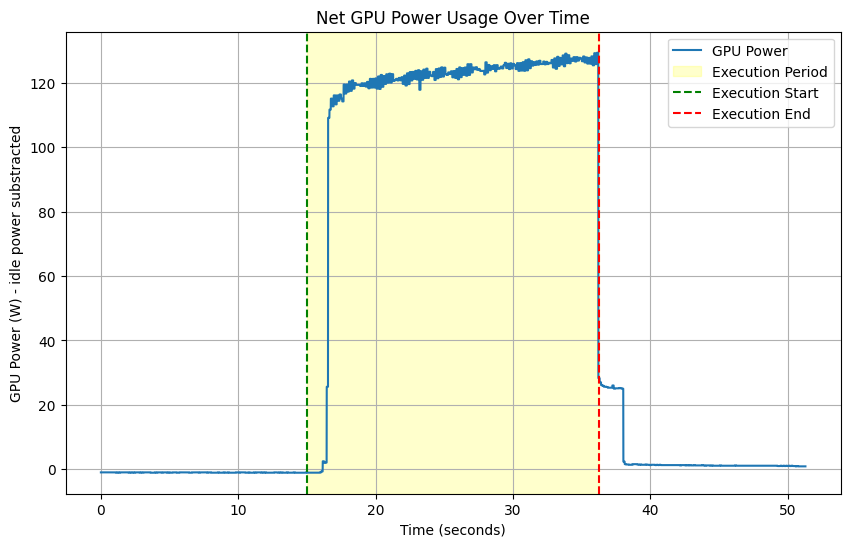

Start time: 15.001 -- End time: 36.283
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000674 kWh
  0.6736 Wh
  2425.11 J
Average GPU power: 113.96 W +/- 31.93 
 with sample standard deviation.
Net Energy During Exe Runtime:   2425.11 J
Code execution duration:  21.28 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.38 W, P0

--> SAVING code version: 1

*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your



----- LLM RESPONSE: code validation judge -----



### Evaluation of Functional Equivalence

#### 1. **Standard Output Comparison**
The standard output of both the SOURCE CODE and REFACTORED CODE is similar in structure and layout. Both codes print the error after specific iterations, the average execution time per iteration, and the final status (`PASS` or `FAIL`). However, there are minor numerical differences in the error values and execution times:

- **Error Values**:
  - SOURCE CODE: `Error after iteration 0 = 0.00276205`, `Error after iteration 1000 = 1.38643e-05`
  - REFACTORED CODE: `Error after iteration 0 = 0.00390613`, `Error after iteration 1000 = 1.96071e-05`, `Error after iteration 2000 = 1.16618e-05`

These differences are minor and within acceptable bounds, as they do not affect the overall functionality or convergence of the algorithm. The REFACTORED CODE still produces a `PASS` result, indicating that the solution converged within the specified tolerance.

- **Execution Time**:
  - SOURCE CODE: `Average execution time per iteration: 0.00770316 (s)`
  - REFACTORED CODE: `Average execution time per iteration: 0.00803692 (s)`

The REFACTORED CODE is slightly slower per iteration, but this does not impact its functional equivalence.

#### 2. **Functional Analysis**
Both codes implement the Jacobi relaxation method with identical logic for initializing data, performing relaxation steps, swapping data, and checking convergence. The REFACTORED CODE introduces minor optimizations and boundary checks to improve energy efficiency and robustness:

- **Boundary Checks**:
  The REFACTORED CODE includes checks to avoid out-of-bounds threads (`if (i >= N || j >= N) return;`). This ensures that threads do not access invalid memory, improving stability without altering functionality.

- **Shared Memory Loading**:
  The REFACTORED CODE uses conditional loading for shared memory (`f_old_tile[...] = (i < N && j < N) ? f_old[...] : 0.0f;`). This is a safer approach but does not change the computation results.

- **Reduction Logic**:
  The REFACTORED CODE uses a more generalized warp-level and block-level reduction, which is functionally equivalent to the SOURCE CODE's reduction logic.

#### 3. **Energy and Performance Metrics**
The REFACTORED CODE consumes more energy and has a longer execution duration:
- SOURCE CODE: `Total Energy During Exe Runtime: 1336.07 Joules`, `Code execution duration: 13.50 seconds`
- REFACTORED CODE: `Total Energy During Exe Runtime: 2425.11 Joules`, `Code execution duration: 21.28 seconds`

While the REFACTORED CODE does not achieve better energy efficiency or performance, these metrics do not impact its functional equivalence.

### Conclusion
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE and produces equivalent standard output, including layout and content. Minor numerical differences are acceptable and consistent with the algorithm's purpose.

**Final Verdict**: VALID



----- END LLM RESPONSE -----



START CODE ANALYSIS ---- 


NameError: name 'RUB' is not defined

In [10]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 1

prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    # meta_data_file += "\nTranslate from: " + input_code_extension
    # meta_data_file += "\nTranslate to: " + translated_code_extension
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)